In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

**1.0 - Data Cleaning**

In [2]:
# 1.1 - Checking "groceries items"

In [3]:
df_groceries = pd.read_csv("us_average_prices_monthly (1.csv", sep=None, engine="python")

# Convert dates to datetime for consistent monthly alignment across datasets.

df_groceries["date"] = pd.to_datetime(df_groceries["date"])

# Focus on January 2015 through December 2025 (11 calendar years).

# Filtering data.

df_groceries = df_groceries[df_groceries["date"] < "2026-01-01"]

# Creating pivot table.

df_groceries__items = pd.pivot_table(df_groceries, values="price", index='date' , columns="item")

# Checking null values.

df_groceries__items.isna().sum().sort_values(ascending=False)

# Calculate the proportion of missing monthly prices for each item.

df_groceries__items.isna().mean().sort_values(ascending=False)

# Retain items with at most 9% missing observations (up to 11 of 132 months).
# This is a project-specific threshold, not a universal rule; 50 of 74 items remain.
# Note that overall completeness does not guarantee complete coverage at both endpoints.

df_groceries__items = df_groceries__items.loc[:, df_groceries__items.isna().mean() <= 0.09]

# Recheck missingness after filtering items:

df_groceries__items.isna().mean().sort_values(ascending=False)

# Examine missingness by month; many items are missing exactly one observation.

df_groceries__items.isna().sum(axis=1).sort_values(ascending=False)

# October 2025 is missing 47 of the 50 retained item prices.
# Fill internal gaps by linear interpolation; do not extrapolate at series endpoints.
# October 2025 estimates are especially uncertain and should be flagged in our presenation.

df_groceries__items = df_groceries__items.interpolate(method="linear", limit_area="inside")

# Verify missing values after interpolation. Preserve the original long-form

df_groceries__items.isna().sum()

item
All Ham (Excluding Canned Ham and Luncheon Slices)           0
All Other Pork (Excluding Canned Ham and Luncheon Slices)    0
All Pork Chops                                               0
All Uncooked Beef Roasts                                     0
All Uncooked Beef Steaks                                     0
All Uncooked Other Beef (Excluding Veal)                     0
All uncooked ground beef                                     0
American processed cheese                                    0
Automotive diesel fuel                                       0
Bacon, sliced                                                0
Bananas                                                      0
Beans, dried, any type, all sizes                            0
Bread, white, pan                                            0
Bread, whole wheat, pan                                      0
Cheddar cheese, natural                                      0
Chicken breast, boneless                          

In [4]:
# 1.1.1 - Creating a dataframe for categories.

# Creating pivot table.

df_categories = pd.pivot_table(df_groceries, values="price", index='date' , columns="category")

# Checking null values.

df_categories.isna().sum().sort_values(ascending=False)

# Calculate the proportion of missing monthly prices for each item.

df_categories.isna().mean().sort_values(ascending=False)

# Retain items with at most 9% missing observations.
# Note that overall completeness does not guarantee complete coverage at both endpoints.

df_categories = df_categories.loc[:, df_categories.isna().mean() <= 0.09]

# Recheck missingness after filtering items:

df_categories.isna().mean().sort_values(ascending=False)

# Same case from the items dataset. 
# Fill internal gaps by linear interpolation; do not extrapolate at series endpoints.
# October 2025 estimates are especially uncertain and should be flagged in our presentation.

df_categories = df_categories.interpolate(method="linear", limit_area="inside")

# Verify missing values after interpolation. Preserve the original long-form

df_categories.isna().sum()

category
Bakery and grains       0
Beef                    0
Dairy and fats          0
Drinks                  0
Eggs                    0
Energy                  0
Fruit                   0
Meat, broad category    0
Pantry and snacks       0
Pork and deli           0
Poultry                 0
Vegetables              0
dtype: int64

In [5]:
# 1.2 - Checking "Consumer Price Index"

In [6]:
df_index = pd.read_csv("Consumer_Price_Index.csv", sep=None, engine="python")

# Checking data type.

df_index.info()

# Transforming "observation_date" into date type.

df_index["observation_date"] = pd.to_datetime(df_index["observation_date"])
df_index.info()

# Setting new columns names.

columns = {
    "observation_date": "date",
    "CPIULFSL": "Consumer_Price_Index"}

df_index.rename(columns=columns, inplace=True)

# Filtering Data (2015-2025)

df_index = df_index[(df_index['date'] > "2014-12-01") & (df_index['date'] < "2026-01-01")]
df_index

# Checking missing values.

df_index.isna().sum()

# Checking which month is null.

df_index[df_index["Consumer_Price_Index"].isna()]

# October 2025 is missing in the CPI-excluding-food series (CPIULFSL).
# Estimate the missing index observation by linear interpolation. Highlight this situation in our presentation. 

df_index = df_index.interpolate(method="linear", limit_area="inside")
df_index.isna().sum()

# Setting "date" as the index of the dataset.

df_index = df_index.set_index("date")
df_index

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 957 entries, 0 to 956
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  957 non-null    object 
 1   CPIULFSL          956 non-null    float64
dtypes: float64(1), object(1)
memory usage: 15.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 957 entries, 0 to 956
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   observation_date  957 non-null    datetime64[ns]
 1   CPIULFSL          956 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 15.1 KB


,Consumer_Price_Index
date,
2015-01-01,232.969
2015-02-01,233.611
2015-03-01,234.411
2015-04-01,234.707
2015-05-01,235.571
...,...
2025-08-01,320.497
2025-09-01,321.478
2025-10-01,321.925


In [7]:
# 1.3 - Checking "Average Wage"

In [8]:
df_wage = pd.read_csv("Average_Hourly_Wages.csv", sep=None, engine="python")

# Checking Data type

df_wage.info()

# Transforming "date" into date time. 

df_wage["observation_date"] = pd.to_datetime(df_wage["observation_date"])
df_wage.info()

# Setting new column names.

columns_wage = {
    "observation_date": "date",
    "CES0500000003": "Average_Hourly_Wage"
}

df_wage.rename(columns=columns_wage, inplace=True)

# Filtering Data (2015 - 2025).

df_wage = df_wage[(df_wage["date"] > "2014-12-01") & (df_wage["date"] < "2026-01-01")]
df_wage

# Checking missing values.

df_wage.isna().sum()

# Setting "date" as the index for the dataset.

df_wage = df_wage.set_index("date")
df_wage

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  247 non-null    object 
 1   CES0500000003     247 non-null    float64
dtypes: float64(1), object(1)
memory usage: 4.0+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   observation_date  247 non-null    datetime64[ns]
 1   CES0500000003     247 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 4.0 KB


,Average_Hourly_Wage
date,
2015-01-01,24.74
2015-02-01,24.79
2015-03-01,24.85
2015-04-01,24.89
2015-05-01,24.97
...,...
2025-08-01,36.62
2025-09-01,36.70
2025-10-01,36.85


**2.0 - Merging datasets (Consumer Price Index and Average Wage)**

In [9]:
# Join all three datasets on their monthly date indexes (inner join).
# Confirm the result has the expected 132 months and 52 columns, and check missing values.

df_join = [df_index, df_wage]

df_project_items = df_groceries__items.join(df_join, how="inner")
df_project_items.isna().sum()

# Join all three datasets for categories.
# Confirm the result has the expected 132 months and 52 columns, and check missing values.

df_join_cat = [df_index, df_wage]
df_project_categories = df_categories.join(df_join_cat, how="inner")
df_project_categories.isna().sum()

# Both datasets were created from the same original grocery dataset.
# The 9% missing-value threshold was applied independently to items
# and categories, followed by linear interpolation.
# Category averages may include items excluded from the item-level dataset.
# I can change it if you want to. 

Bakery and grains       0
Beef                    0
Dairy and fats          0
Drinks                  0
Eggs                    0
Energy                  0
Fruit                   0
Meat, broad category    0
Pantry and snacks       0
Pork and deli           0
Poultry                 0
Vegetables              0
Consumer_Price_Index    0
Average_Hourly_Wage     0
dtype: int64

**3.0 - Question 1: Which grocery categories experienced the highest price increases between 2015 and 2025?**

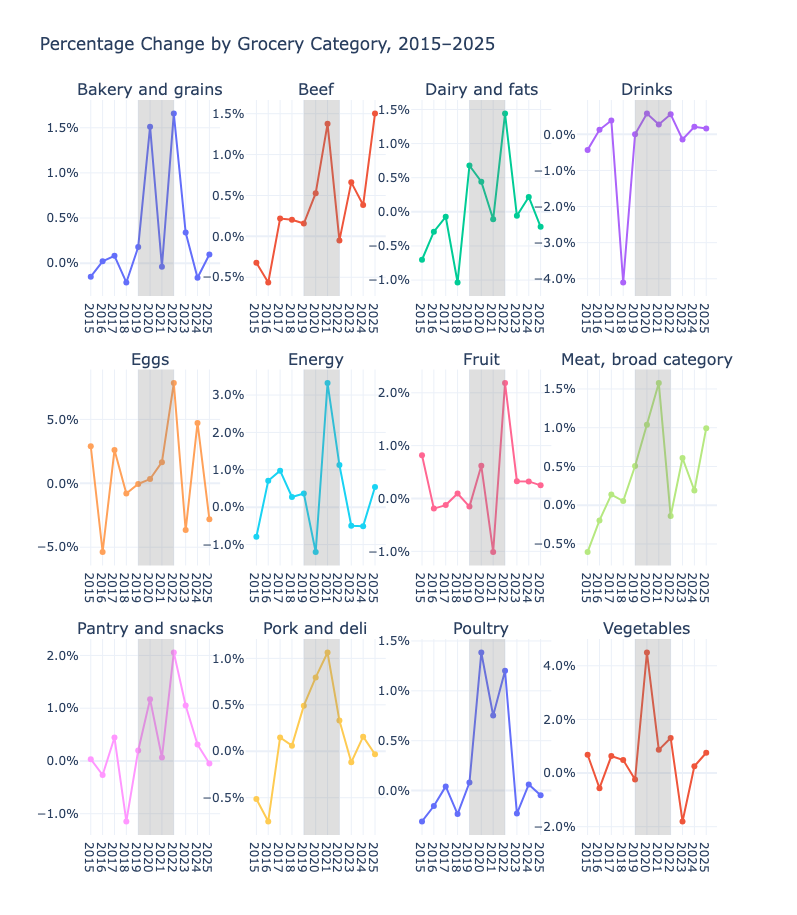

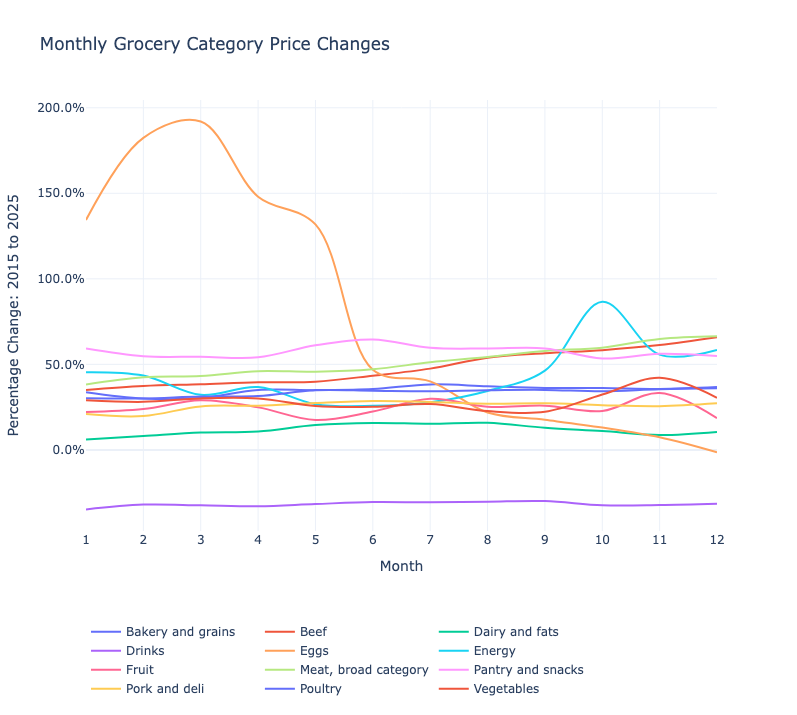

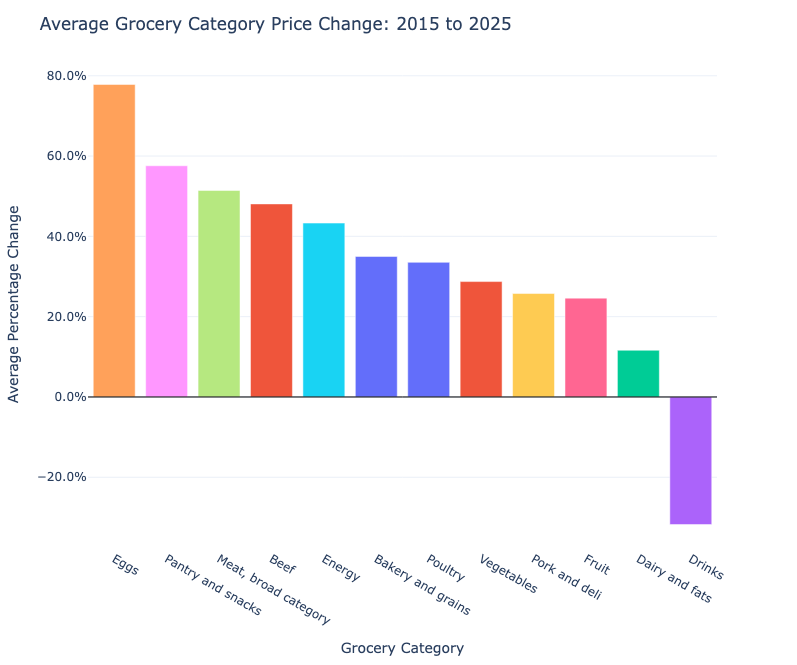

In [74]:
# Creating the df with only the categories and the percentage changing. 
df_pct_cat_monthly = df_project_categories.pct_change()

df_pct_cat_monthly = df_pct_cat_monthly.loc[:, 
    (df_pct_cat_monthly.columns != "Consumer_Price_Index") &
     (df_pct_cat_monthly.columns != "Average_Hourly_Wage")]
# Dropping the first row (Null row, no previous data)

df_pct_cat_monthly = df_pct_cat_monthly.dropna(how="all")

# Creating pivot table per year.

df_pct_pivot = df_pct_cat_monthly.pivot_table(
    index = df_pct_cat_monthly.index.year,
    aggfunc="mean")

# Creating interactive plots for each category.

import plotly.graph_objects as go
from plotly.subplots import make_subplots

categories = df_pct_pivot.columns

fig = make_subplots(
    rows=3,
    cols=4,
    subplot_titles=categories,
    horizontal_spacing=0.04,
    vertical_spacing=0.10
)

for i, column in enumerate(categories):
    row = (i // 4) + 1
    col = (i % 4) + 1

    fig.add_trace(
        go.Scatter(
            x=df_pct_pivot.index,
            y=df_pct_pivot[column],
            mode="lines+markers",
            name=column,
            hovertemplate=(
                f"Category: {column}<br>"
                "Year: %{x}<br>"
                "Change: %{y:.2%}"
                "<extra></extra>"
            )
        ),
        row=row,
        col=col
    )

    fig.add_vrect(
        x0=2019,
        x1=2022,
        fillcolor="gray",
        opacity=0.25,
        line_width=0,
        row=row,
        col=col
    )

fig.update_layout(
    title="Percentage Change by Grocery Category, 2015–2025",
    width=1400,
    height=900,
    template="plotly_white",
    showlegend=False
)

fig.update_xaxes(dtick=1)
fig.update_yaxes(tickformat=".1%")

fig.show()

## These plots I created using AI because they are interactive. 

# Answering the question. 

# Gathering values from 2015 to 2025

df_price_changes = df_project_categories.loc[((df_project_categories.index.year == 2015) | (df_project_categories.index.year == 2025)), :]

df_price_changes = df_price_changes.loc[:, 
    (df_price_changes.columns != "Consumer_Price_Index") &
    (df_price_changes.columns != "Average_Hourly_Wage")]

# Creating one df for each year

price_2015 = df_price_changes[df_price_changes.index.year == 2015].copy()
price_2025 = df_price_changes[df_price_changes.index.year == 2025].copy()

price_2015.index = price_2015.index.month
price_2025.index = price_2025.index.month

# Gathering the change between months of both years. 

monthly_difference = (price_2025 - price_2015)
monthly_change_pct = monthly_difference / price_2015
monthly_change_pct

# Plotting

fig = go.Figure()

for column in monthly_change_pct.columns:
    fig.add_trace(
        go.Scatter(
            x=monthly_change_pct.index,
            y=monthly_change_pct[column],
            mode="lines",
            name=column,
            line_shape="spline",
            hovertemplate=(
                "Category: %{fullData.name}<br>"
                "Month: %{x}<br>"
                "Change: %{y:.2%}"
                "<extra></extra>"
            )
        )
    )

fig.update_layout(
    title="Monthly Grocery Category Price Changes",
    width=1200,
    height=700,
    xaxis_title="Month",
    yaxis_title="Percentage Change: 2015 to 2025",
    xaxis=dict(dtick=1),
    yaxis=dict(tickformat=".1%"),
    hovermode="closest",
    template="plotly_white",
    legend=dict(
        orientation="h",
        y=-0.2,
        x=0
    ),
    margin=dict(b=130)
)

fig.show()

### These plots I created using AI because they are interactive. 


# Ranking the mean per category. 

monthly_change_pct_mean = monthly_change_pct.mean()

monthly_change_pct_mean.sort_values(ascending=False)

# Plotting the mean final.
import plotly.express as px

categories = monthly_change_pct.columns
plotly_colors = px.colors.qualitative.Plotly

category_colors = {
    category: plotly_colors[i % len(plotly_colors)]
    for i, category in enumerate(categories)
}

ranked_categories = (
    monthly_change_pct_mean
    .sort_values(ascending=False)
    .rename("average_percentage_change")
    .reset_index()
)

ranked_categories.columns = ["category", "average_percentage_change"]

fig = px.bar(
    ranked_categories,
    x="category",
    y="average_percentage_change",
    color="category",
    color_discrete_map=category_colors,
    hover_data={
        "category": True,
        "average_percentage_change": ":.2%"
    }
)

fig.update_layout(
    title="Average Grocery Category Price Change: 2015 to 2025",
    xaxis_title="Grocery Category",
    yaxis_title="Average Percentage Change",
    template="plotly_white",
    width=1200,
    height=650,
    showlegend=False
)

fig.update_yaxes(tickformat=".1%")
fig.add_hline(y=0, line_width=1, line_color="black")

fig.show()

In [3]:
# ============================================================
# NOTES
# ============================================================

# 1. DATASETS
# Two merged datasets were created:
# df_project_items: Monthly prices for individual items, CPI, and hourly wages.
# df_project_categories: Monthly category-level average prices, CPI, and hourly wages.
# Both datasets cover January 2015 through December 2025.

# 2. GROCERY CATEGORIES
# Category prices were calculated using the mean of individual item prices.
# Since products have different units, these averages should not be interpreted
# as representative grocery costs.
# Consider using percentage changes or normalized price indexes for comparisons.

# 3. FOOD VS. NON-FOOD ITEMS
# The original dataset includes gasoline, electricity, fuel oil, and other
# non-food products. Should we separate these when conducting grocery-specific analyses?

# 4. INFLATION RATE
# Consumer_Price_Index represents CPI excluding food (CPIULFSL), not inflation.
# We have to calculate month-over-month or year-over-year percentage changes
# before conducting regression or correlation analyses.

# 5. WAGE GROWTH
# Average_Hourly_Wage represents hourly earnings in dollars.
# Consider calculating percentage changes to compare wage growth with
# inflation and grocery price increases.

# 6. INTERPOLATED VALUES
# Missing observations were estimated using linear interpolation.
# October 2025 had substantial missing data, particularly for individual items.
# Results involving interpolated observations should be interpreted cautiously.